# Topical Lectures, Controls 
## 2D simulator, part 5: the race
Andreas Freise, Bas Swinkels 30.10.2026

In this notebook, we will try to fly our drone model, using the controls we developed in the previous notebooks. To make it a bit more fun, we pose the following challenge: fly your drone through a set of predefined markers and report the time. We will compare the best times at the end of the project.

Among the extra notebooks are an interactive version, in which you fly the same track with the keyboard, and two model-based controllers for the same task.

Here the race is flown by a preprogrammed sequence of setpoints, without an interactive plot.

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import time
import module
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning) 

# inline plots again
%matplotlib inline

# Don't forget to set the name string to your own name
MyName = "Caspar"

Below we set the calibration constants from the system identification and provide the motor-mixing helpers. The velocity-loop cascade controllers are set up in the cell after.

In [22]:
# Calibration constants of your drone, from the system identification:
# copy the values printed at the end of that notebook here.
# The numbers below are those of the drone of "Caspar".
V_left_offset = 0.00135   # throttle units; cancels left/right asymmetry
V_hover = 0.5331          # per-motor throttle at hover (= M*g/2 / amp)
V_max = 1.0               # throttle range upper bound
V_min = 0                 # motors are single-direction

# Common-mode / differential decomposition for motor mixing.
# The total motor voltage must stay in [V_min, V_max]; the differential is
# bounded by the headroom that the common-mode thrust leaves on each side.

def set_v(drone, _V_left, _V_right):
    V_left = V_hover + _V_left + V_left_offset
    V_right = V_hover + _V_right
    fb_z = (V_left + V_right) / 2
    fb_phi = (V_left - V_right) / 2
    fb_z = max(V_min, min(fb_z, V_max))
    headroom = min(fb_z - V_min, V_max - fb_z)
    fb_phi = max(-headroom, min(fb_phi, headroom))
    drone.set_V(fb_z + fb_phi, fb_z - fb_phi)

def set_v_nohover(drone, _V_left, _V_right):
    V_left = _V_left + V_left_offset
    V_right = _V_right
    fb_z = (V_left + V_right) / 2
    fb_phi = (V_left - V_right) / 2
    fb_z = max(V_min, min(fb_z, V_max))
    headroom = min(fb_z - V_min, V_max - fb_z)
    fb_phi = max(-headroom, min(fb_phi, headroom))
    drone.set_V(fb_z + fb_phi, fb_z - fb_phi)

def zphi2V(fb_z, fb_phi):
    V_left = fb_z + fb_phi
    V_right = fb_z - fb_phi
    return V_left, V_right


In [23]:
# Velocity-loop cascade controllers, as in 2Dsim_04, with the gains
# re-tuned for race time. The limits stay at the Crazyflie firmware values
# (1 m/s, 20 deg), so the time compares with what the real drone can do.
# Stiffer position loops, and integrators in the velocity loops so the drone
# holds its speed against the wind.
y_pos_ctrl = module.PIDController(Kp=-3.2, Ki=0,    Kd=0)
z_pos_ctrl = module.PIDController(Kp=-8.0, Ki=0,    Kd=0)
y_vel_ctrl = module.PIDController(Kp=1.3,  Ki=1.0,  Kd=0)
z_vel_ctrl = module.PIDController(Kp=-0.4, Ki=-1.8, Kd=0)
phi_ctrl   = module.PIDController(Kp=0.2,  Ki=0,    Kd=0.022)
v_max      = 1.0                # m/s, the limit on the velocity setpoint
tilt_max   = 20 * np.pi / 180   # rad


## Racing your drone

Again, to test our new control loops we are going to race our drone through a simple track. The goal is to reach a pre-defined set of targets as quickly as possible.

Below we run a preprogrammed control loop that steps through the targets in order, switching the setpoints `y0`, `z0` to the next target each time the drone reaches the current one. We collect the trajectory and plot it afterwards, then replay the run as an inline video.

In [24]:
drone = module.Drone(name=MyName, wind=True)

# Defining the track as an array of targets [y, z, radius] in metres.
targets = np.array([
    [ 1.0,  1.5, 0.1],
    [ 1.0, -1.5, 0.1],
    [-1.0, -1.5, 0.1],
    [-1.0,  1.5, 0.1],
    [   0,    0, 0.1]
])
drone.set_targets(targets)

# Running for 200 seconds
N = 200 * 60
Nidx = N - 1
results = np.zeros([N, 14])
V_left = V_right = 0

for ctrl in (y_pos_ctrl, z_pos_ctrl, y_vel_ctrl, z_vel_ctrl, phi_ctrl):
    ctrl.reset()

for i in range(N):
    state = drone.update()
    results[i, 0:12] = module.state_to_array(state)
    results[i, 12:14] = [V_left, V_right]

    idx = drone.target_idx
    if idx == drone.num_targets:
        Nidx = i
        break
    y0 = targets[idx, 0]
    z0 = targets[idx, 1]

    # Outer position loops -> desired velocity, saturated at +-v_max.
    dy_des = float(np.clip(y_pos_ctrl(state.y, state.dy, y0),
                           -v_max, v_max))
    dz_des = float(np.clip(z_pos_ctrl(state.z, state.dz, z0),
                           -v_max, v_max))

    # Velocity loops -> desired tilt (y) and thrust correction (z).
    tilt_des = float(np.clip(y_vel_ctrl(state.dy, 0, dy_des),
                             -tilt_max, tilt_max))
    z_corr = z_vel_ctrl(state.dz, 0, dz_des)

    # Inner phi PD follows the tilt setpoint.
    phi_fb = phi_ctrl(state.phi, state.dphi, tilt_des)

    # Mix and send.
    hover_ff = V_hover / np.cos(state.phi)
    V_left, V_right = zphi2V(hover_ff + z_corr, phi_fb)
    set_v_nohover(drone, V_left, V_right)


Total time: 12.35 out of 200.00 seconds


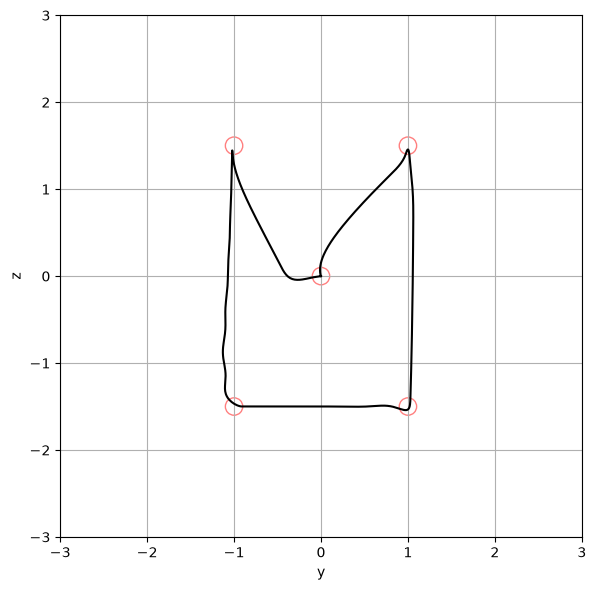

In [25]:
# Plotting the results

start=0
t = results[start:,0]
y = results[start:,1]
z = results[start:,2]
phi = results[start:,3]
dphi = results[start:,6]
fig, ax = plt.subplots(1, figsize=(12,6))
for _t in targets:
    patch = plt.Circle((_t[0],_t[1]),_t[2], lw=1, color='red', alpha=0.5, fill=False)
    ax.add_patch(patch)
plt.plot(y,z, 'k')
ax.set_xlabel("y")
ax.set_ylabel("z")
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_aspect('equal')
plt.grid()
#plt.legend()
plt.tight_layout()

t_end = results[Nidx,0]

print(f"Total time: {t_end:.2f} out of {N/60.0:.2f} seconds")


## Replay the race as an inline video

The race ran headless above. We can now embed an HTML5 video of the recorded trajectory directly into the notebook output. This works in any browser-based notebook (JupyterLab, classic, VS Code, Google Colab) and does not need a Qt backend.


In [26]:
# Trim the results to the part of the run that actually happened
# (the loop above breaks early and leaves trailing zeros if all
# targets were reached before N steps).
module.render_replay(drone, results[:Nidx + 1])


## Optional: the race without the firmware limits

The race above keeps the limits of the Crazyflie firmware, 1 m/s and 20 degrees of tilt. Most of the race time comes from that speed limit: the track is about 10 m long. Below, the same race is flown with the limits raised to 1.5 m/s and 45 degrees, with gains re-tuned for those limits.

This is **not** a result for the real drone: on the real Crazyflie the limits are set by the firmware and the shared course limits. Use it to see how much of the race time is set by the command limits and how much by the gains.

In [27]:
# Limits raised beyond the firmware values: for comparison only.
y_pos_ctrl = module.PIDController(Kp=-3.3, Ki=0,     Kd=0)
z_pos_ctrl = module.PIDController(Kp=-4.5, Ki=0,     Kd=0)
y_vel_ctrl = module.PIDController(Kp=1.4,  Ki=0.2,   Kd=0)
z_vel_ctrl = module.PIDController(Kp=-0.7, Ki=-0.17, Kd=0)
phi_ctrl   = module.PIDController(Kp=0.07, Ki=0,     Kd=0.024)
v_max      = 1.5                # m/s, raised from 1.0
tilt_max   = 45 * np.pi / 180   # rad, raised from 20 deg


In [28]:
# The same race as above, with the controllers of the previous cell.
drone = module.Drone(name=MyName, wind=True)

# Defining the track as an array of targets [y, z, radius] in metres.
targets = np.array([
    [ 1.0,  1.5, 0.1],
    [ 1.0, -1.5, 0.1],
    [-1.0, -1.5, 0.1],
    [-1.0,  1.5, 0.1],
    [   0,    0, 0.1]
])
drone.set_targets(targets)

# Running for 200 seconds
N = 200 * 60
Nidx = N - 1
results = np.zeros([N, 14])
V_left = V_right = 0

for ctrl in (y_pos_ctrl, z_pos_ctrl, y_vel_ctrl, z_vel_ctrl, phi_ctrl):
    ctrl.reset()

for i in range(N):
    state = drone.update()
    results[i, 0:12] = module.state_to_array(state)
    results[i, 12:14] = [V_left, V_right]

    idx = drone.target_idx
    if idx == drone.num_targets:
        Nidx = i
        break
    y0 = targets[idx, 0]
    z0 = targets[idx, 1]

    # Outer position loops -> desired velocity, saturated at +-v_max.
    dy_des = float(np.clip(y_pos_ctrl(state.y, state.dy, y0),
                           -v_max, v_max))
    dz_des = float(np.clip(z_pos_ctrl(state.z, state.dz, z0),
                           -v_max, v_max))

    # Velocity loops -> desired tilt (y) and thrust correction (z).
    tilt_des = float(np.clip(y_vel_ctrl(state.dy, 0, dy_des),
                             -tilt_max, tilt_max))
    z_corr = z_vel_ctrl(state.dz, 0, dz_des)

    # Inner phi PD follows the tilt setpoint.
    phi_fb = phi_ctrl(state.phi, state.dphi, tilt_des)

    # Mix and send.
    hover_ff = V_hover / np.cos(state.phi)
    V_left, V_right = zphi2V(hover_ff + z_corr, phi_fb)
    set_v_nohover(drone, V_left, V_right)


Total time: 9.97 out of 200.00 seconds


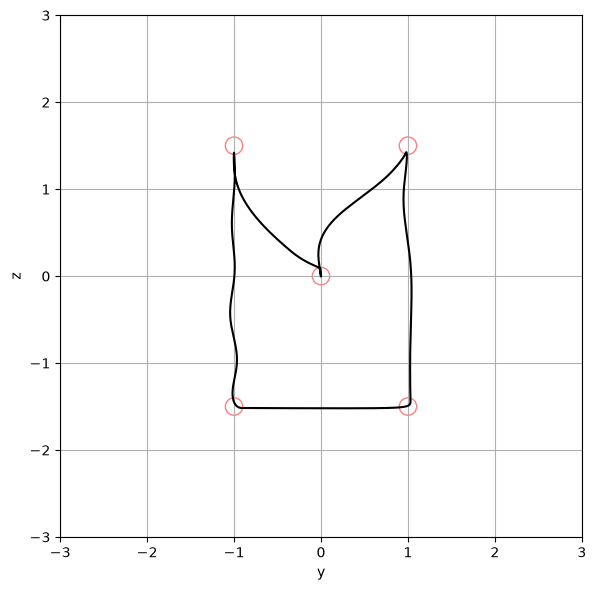

In [29]:
# Plotting the results

start=0
t = results[start:,0]
y = results[start:,1]
z = results[start:,2]
phi = results[start:,3]
dphi = results[start:,6]
fig, ax = plt.subplots(1, figsize=(12,6))
for _t in targets:
    patch = plt.Circle((_t[0],_t[1]),_t[2], lw=1, color='red', alpha=0.5, fill=False)
    ax.add_patch(patch)
plt.plot(y,z, 'k')
ax.set_xlabel("y")
ax.set_ylabel("z")
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_aspect('equal')
plt.grid()
#plt.legend()
plt.tight_layout()

t_end = results[Nidx,0]

print(f"Total time: {t_end:.2f} out of {N/60.0:.2f} seconds")


In [30]:
# Inline video of this run (race, limits raised).
module.render_replay(drone, results[:Nidx + 1])